In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"..\DataInput\Telco-Customer-Churn.csv")

In [9]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
df.shape

(7043, 21)

In [11]:
df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [15]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

In [16]:
blank_total_charges = df["TotalCharges"].str.strip().eq("").sum()

print("Blank TotalCharges:", blank_total_charges)

Blank TotalCharges: 11


In [17]:
string_columns = df.select_dtypes(include=["str", "object"]).columns

for col in string_columns:
    blank_count = df[col].str.strip().eq("").sum()

    if blank_count > 0:
        print(f"{col}: {blank_count} blank values")

TotalCharges: 11 blank values


In [18]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 0


In [19]:
df.loc[
    df["TotalCharges"].str.strip().eq(""),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [20]:
df_clean = df.copy()

In [21]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].str.strip(),
    errors="coerce"
)

In [23]:
print("Missing values:", df_clean["TotalCharges"].isna().sum())

print("Data type:", df_clean["TotalCharges"].dtype)

print(
    df_clean.loc[
        df_clean["tenure"] == 0,
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

Missing values: 0
Data type: float64
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           0.0
753        0           20.25           0.0
936        0           80.85           0.0
1082       0           25.75           0.0
1340       0           56.05           0.0
3331       0           19.85           0.0
3826       0           25.35           0.0
4380       0           20.00           0.0
5218       0           19.70           0.0
6670       0           73.35           0.0
6754       0           61.90           0.0


In [24]:
numerical_cols = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = df_clean.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [25]:
df_clean[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


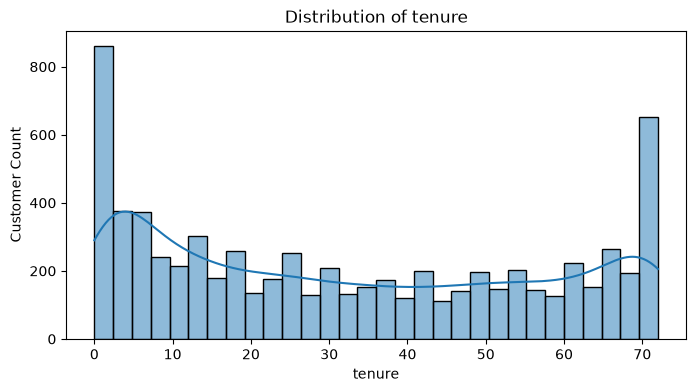

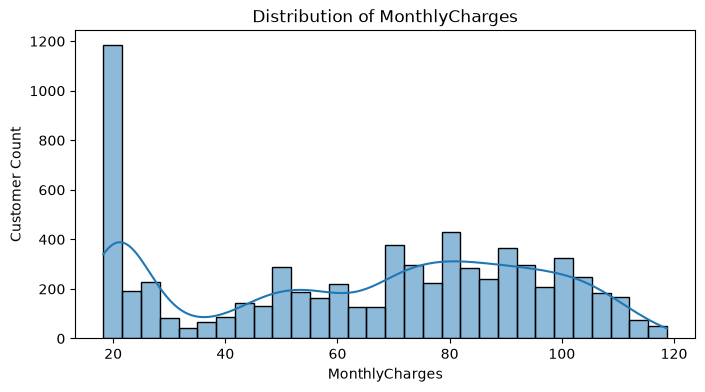

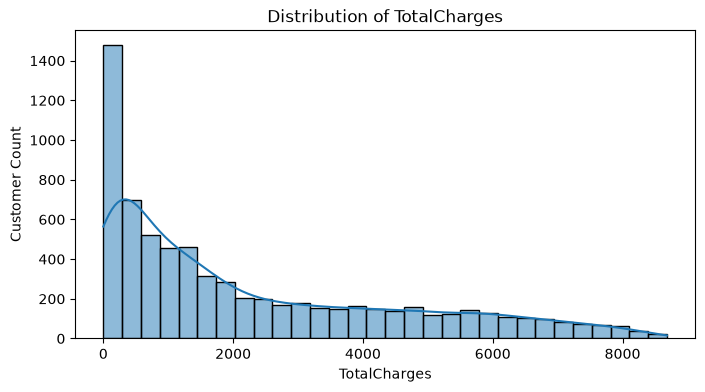

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

continuous_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in continuous_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.show()

In [27]:
for col in categorical_cols:
    print(f"\nFeature: {col}")
    print(df_clean[col].value_counts())


Feature: customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
             ..
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
8361-LTMKD    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

Feature: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Feature: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Feature: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Feature: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Feature: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Feature: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Feature: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Feature: O

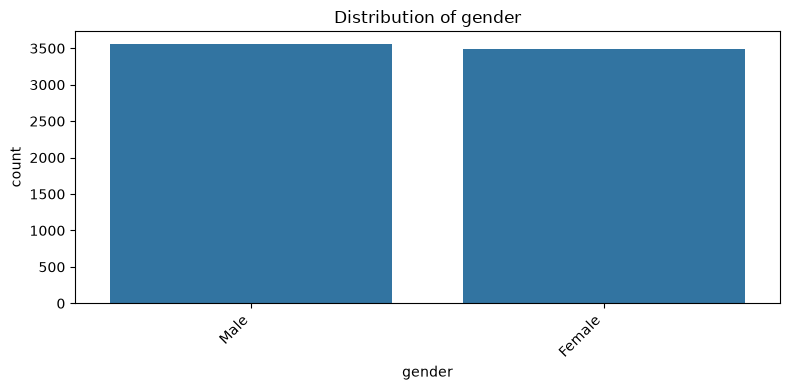

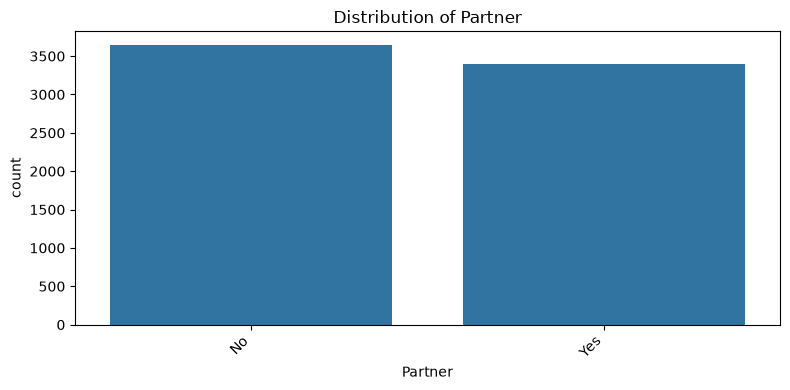

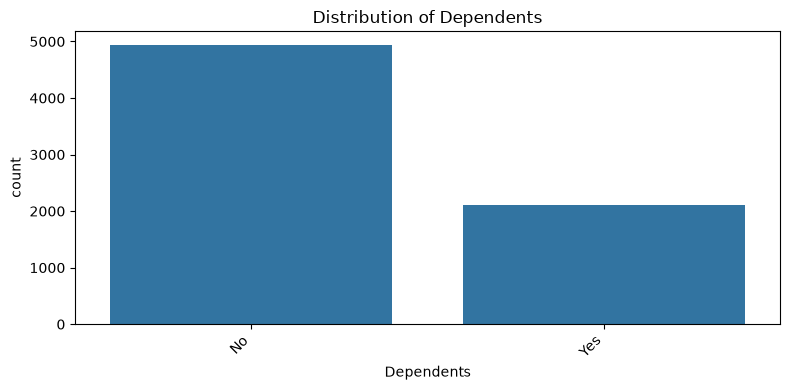

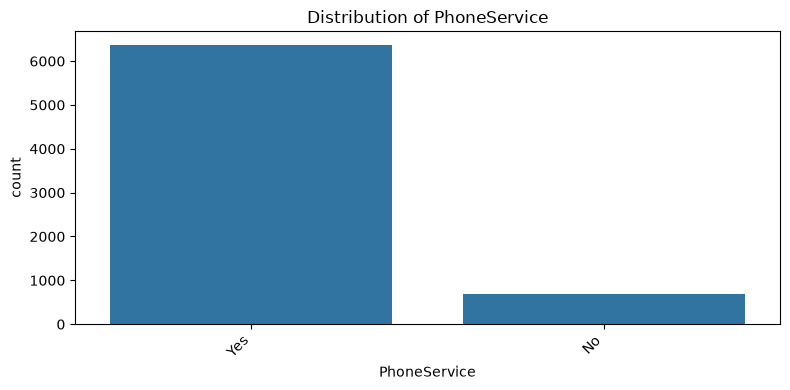

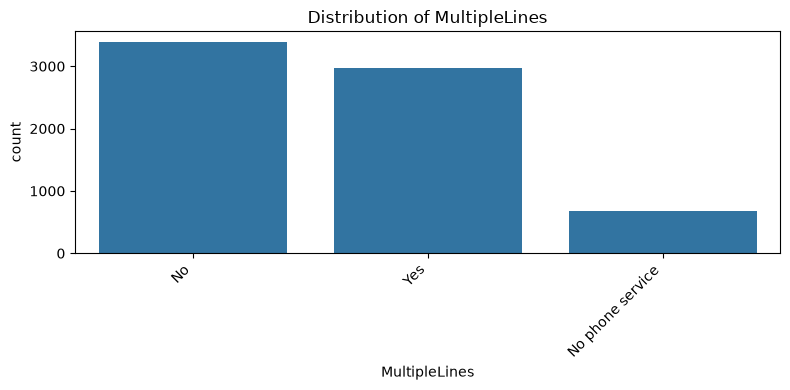

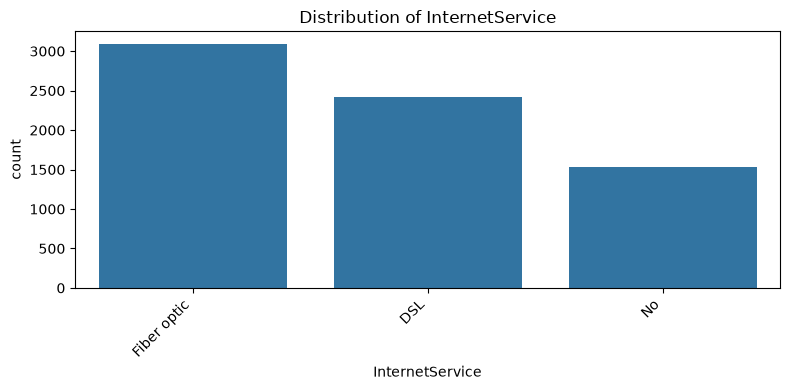

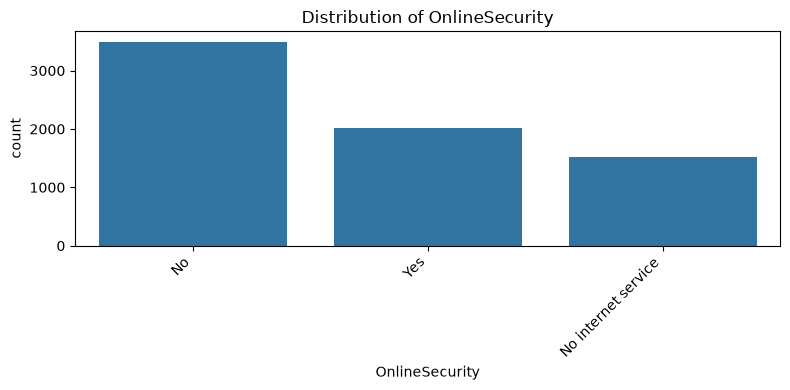

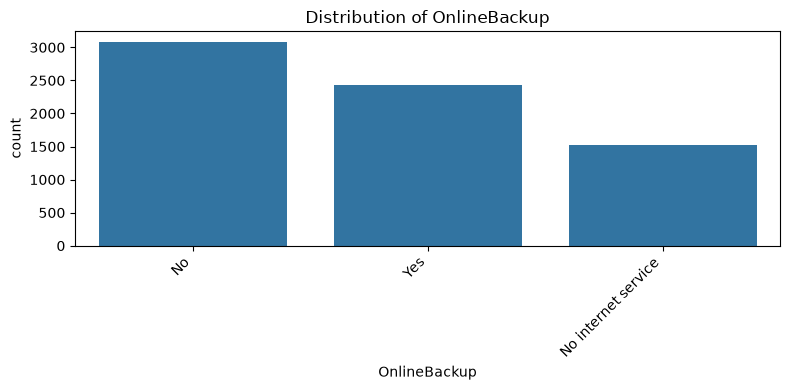

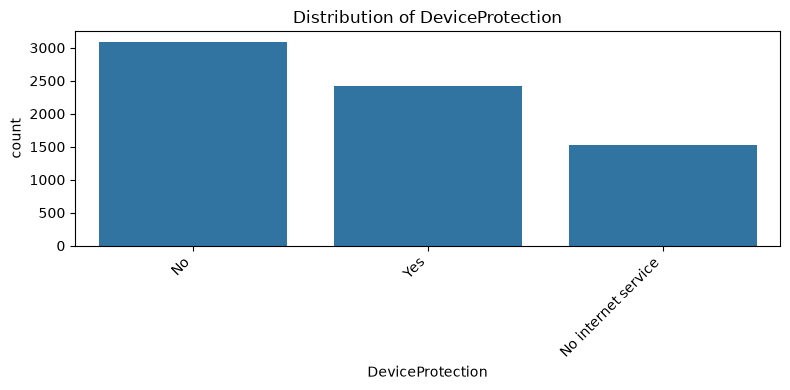

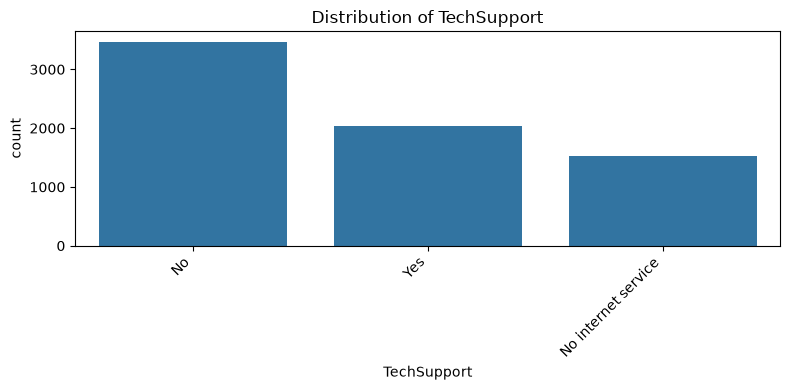

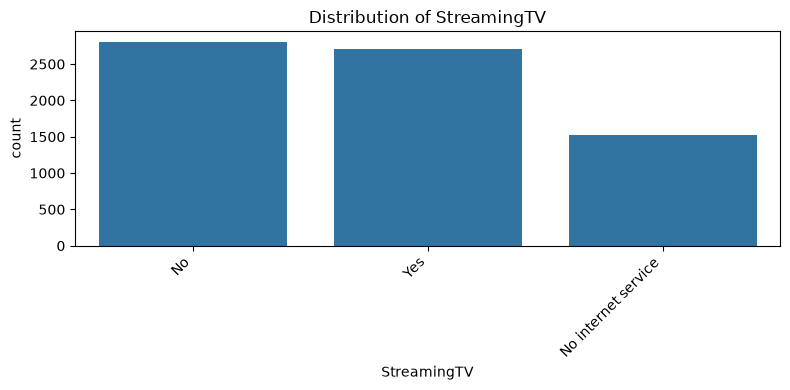

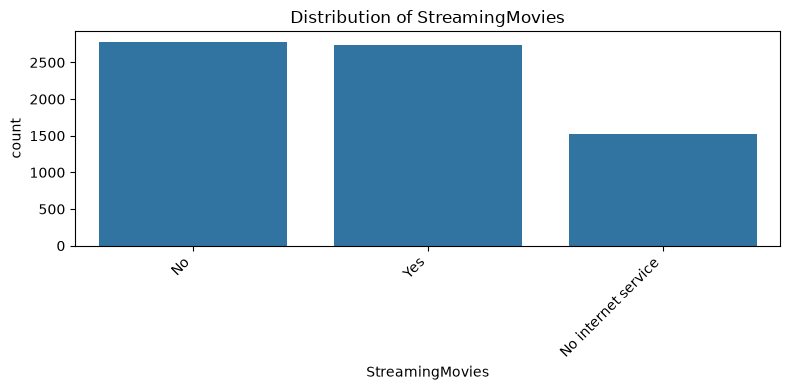

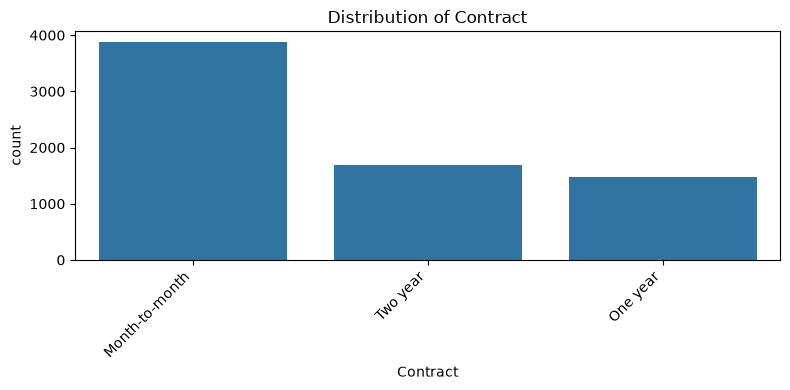

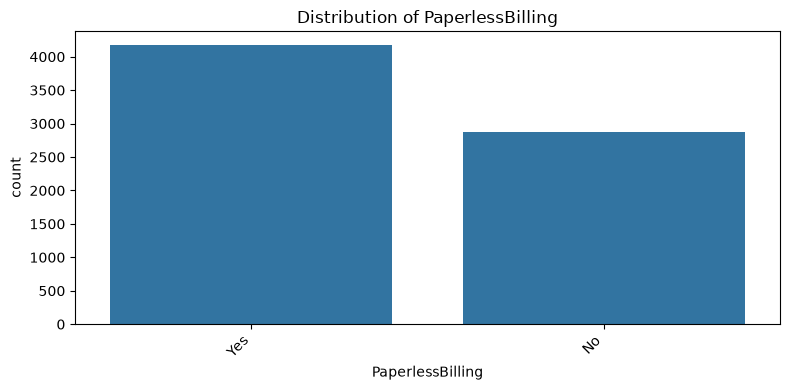

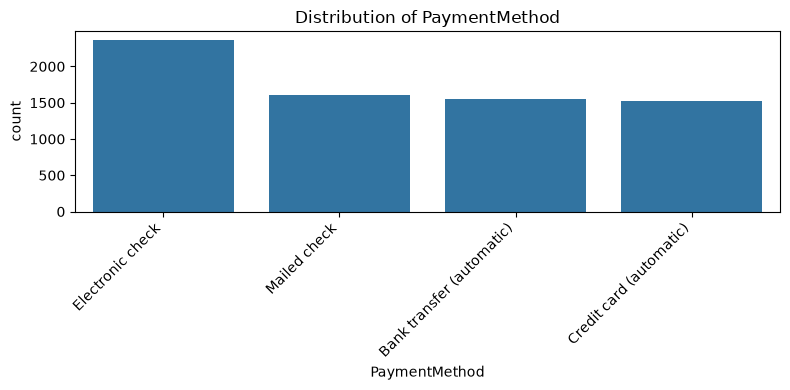

In [28]:
categorical_analysis_cols = [
    col for col in categorical_cols
    if col not in ["customerID", "Churn"]
]

for col in categorical_analysis_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df_clean,
        x=col,
        order=df_clean[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

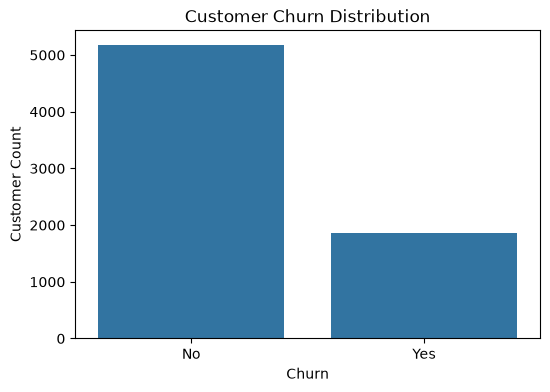

In [29]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_clean,
    x="Churn",
    order=["No", "Yes"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.show()

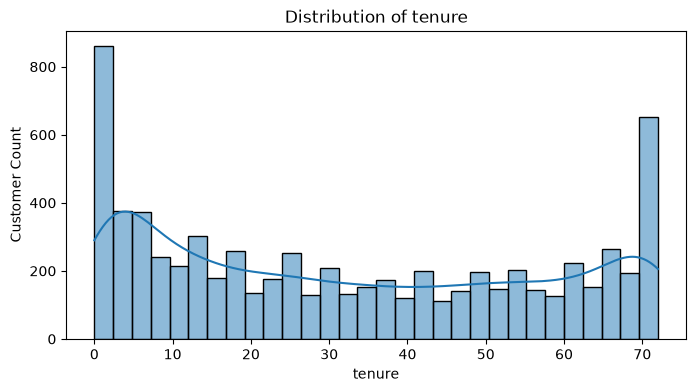

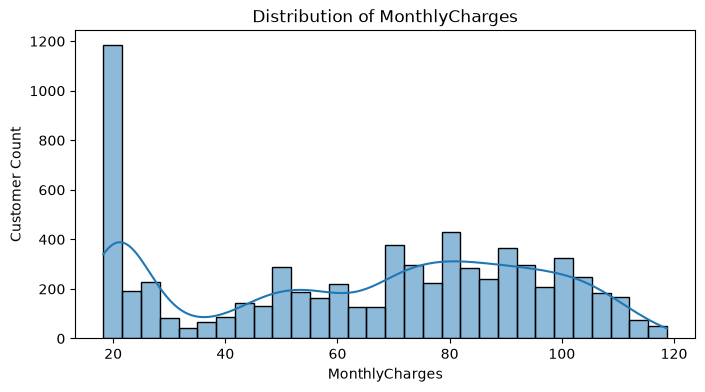

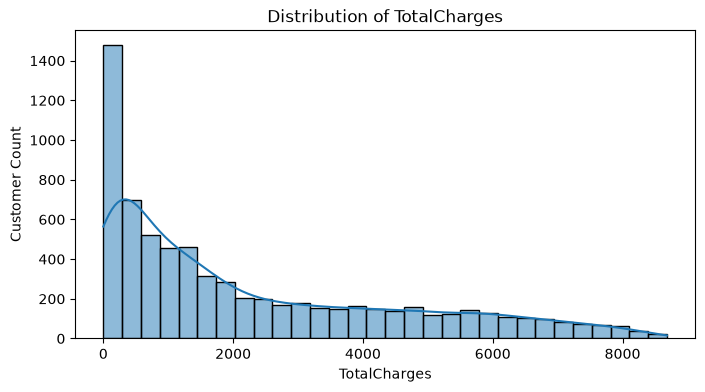

In [31]:
continuous_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in continuous_cols:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.show()

In [32]:
categorical_analysis_cols = [
    col for col in categorical_cols
    if col not in ["customerID", "Churn"]
]

for col in categorical_analysis_cols:
    print(f"\nFeature: {col}")
    print(df_clean[col].value_counts())


Feature: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Feature: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Feature: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Feature: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Feature: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Feature: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Feature: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Feature: OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

Feature: DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet s

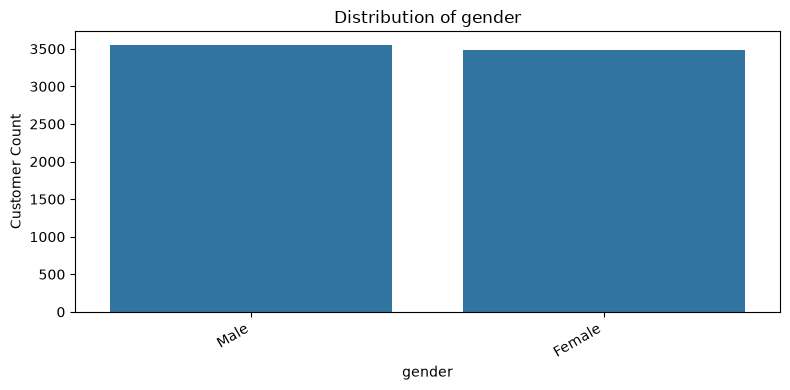

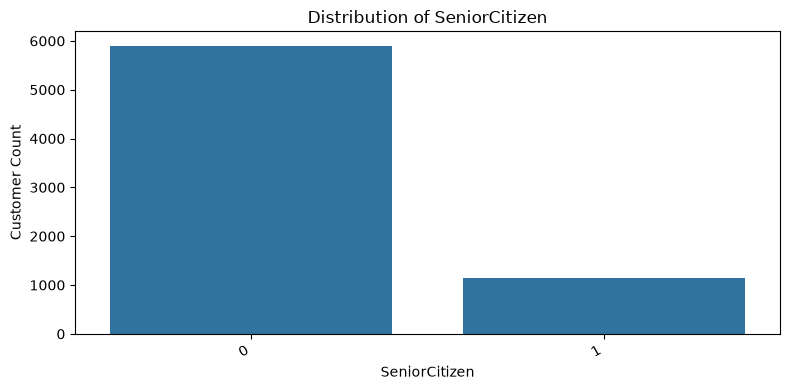

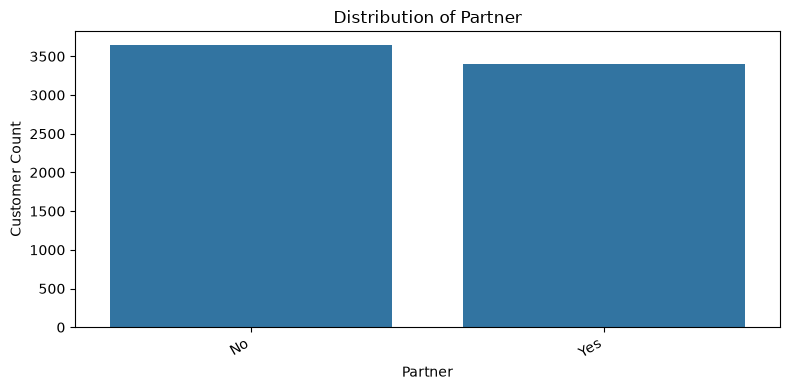

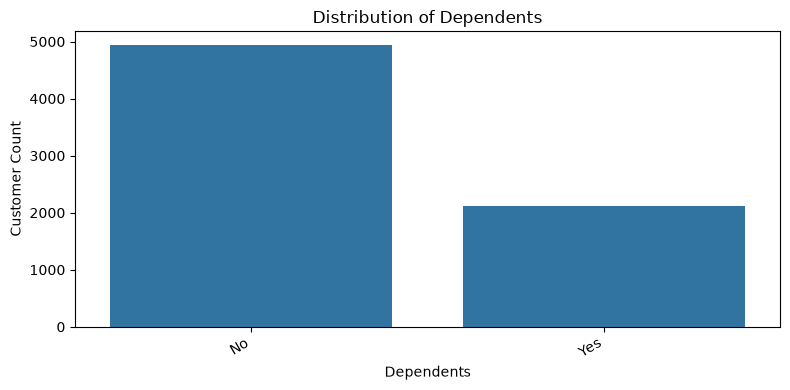

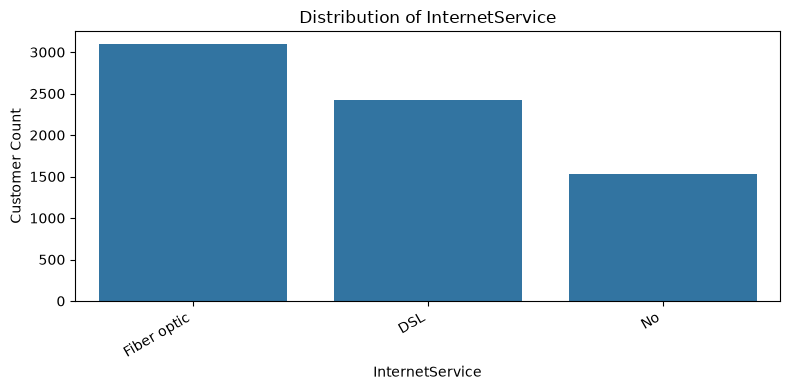

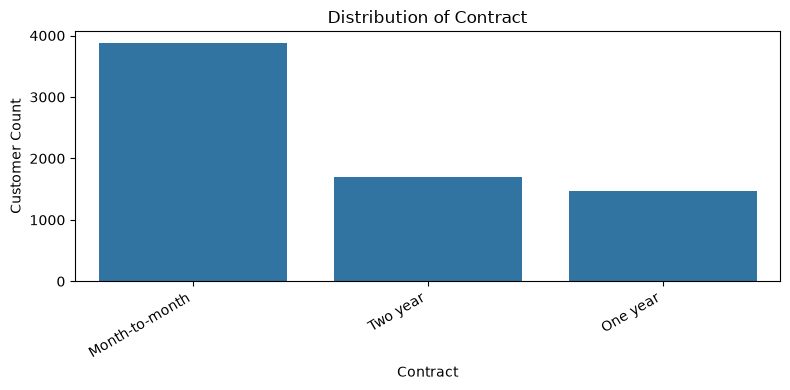

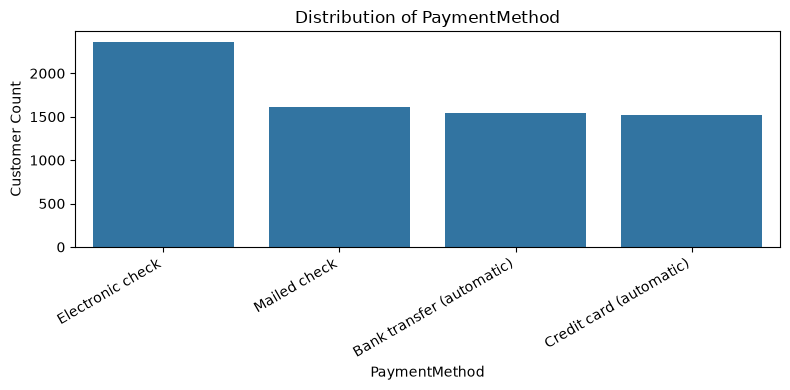

In [33]:
important_categorical_cols = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "InternetService",
    "Contract",
    "PaymentMethod"
]

for col in important_categorical_cols:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df_clean,
        x=col,
        order=df_clean[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

In [34]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

In [35]:
df_clean.groupby("Churn")[numerical_features].agg(
    ["mean", "median", "std", "min", "max"]
).T

Churn                           No          Yes
tenure         mean      37.569965    17.979133
               median    38.000000    10.000000
               std       24.113777    19.531123
               min        0.000000     1.000000
               max       72.000000    72.000000
MonthlyCharges mean      61.265124    74.441332
               median    64.425000    79.650000
               std       31.092648    24.666053
               min       18.250000    18.850000
               max      118.750000   118.350000
TotalCharges   mean    2549.911442  1531.796094
               median  1679.525000   703.550000
               std     2329.954215  1890.822994
               min        0.000000    18.850000
               max     8672.450000  8684.800000

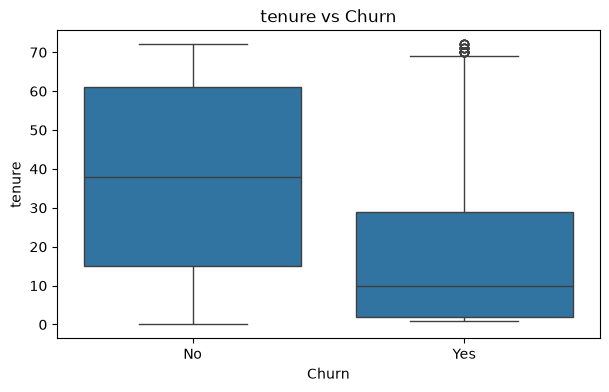

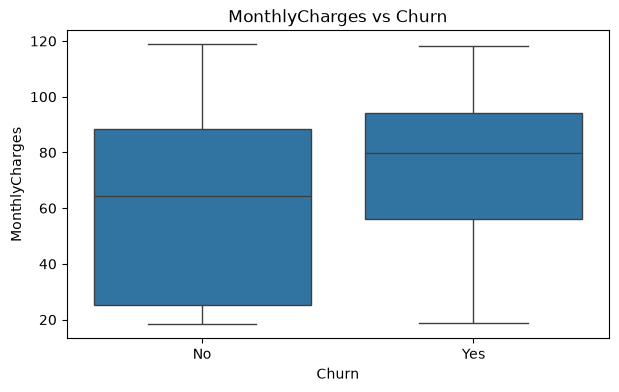

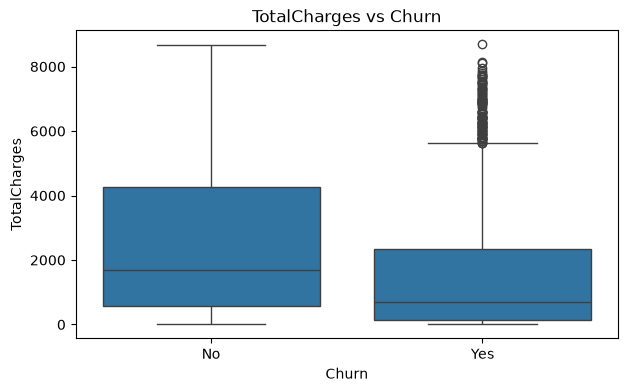

In [36]:
for col in numerical_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df_clean,
        x="Churn",
        y=col
    )

    plt.title(f"{col} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(col)
    plt.show()

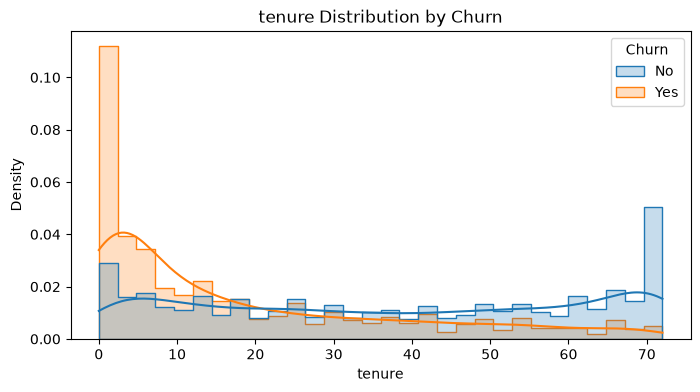

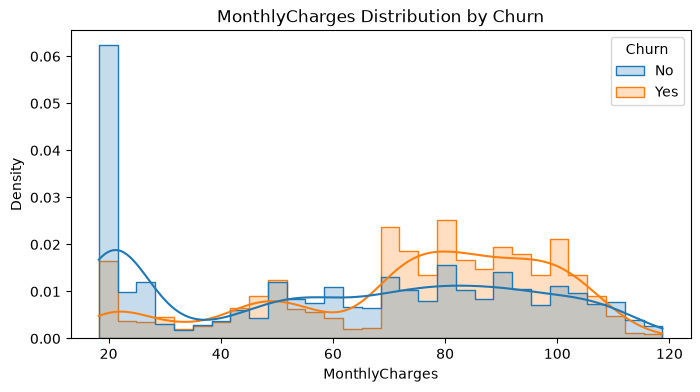

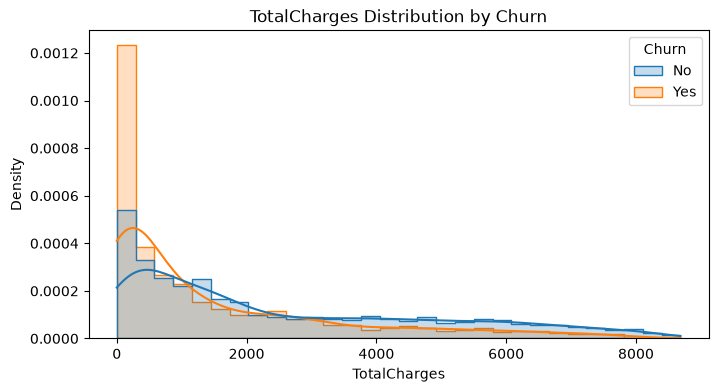

In [37]:
for col in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_clean,
        x=col,
        hue="Churn",
        kde=True,
        bins=30,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{col} Distribution by Churn")
    plt.show()

In [38]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [39]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [40]:
categorical_features = [
    col for col in categorical_cols
    if col not in ["customerID", "Churn"]
]

for col in categorical_features:

    print(f"\nFeature: {col}")

    churn_distribution = pd.crosstab(
        df_clean[col],
        df_clean["Churn"],
        normalize="index"
    ) * 100

    print(churn_distribution)


Feature: gender
Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338

Feature: Partner
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Feature: Dependents
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237

Feature: PhoneService
Churn                No        Yes
PhoneService                      
No            75.073314  24.926686
Yes           73.290363  26.709637

Feature: MultipleLines
Churn                    No        Yes
MultipleLines                         
No                74.955752  25.044248
No phone service  75.073314  24.926686
Yes               71.390104  28.609896

Feature: InternetService
Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No              

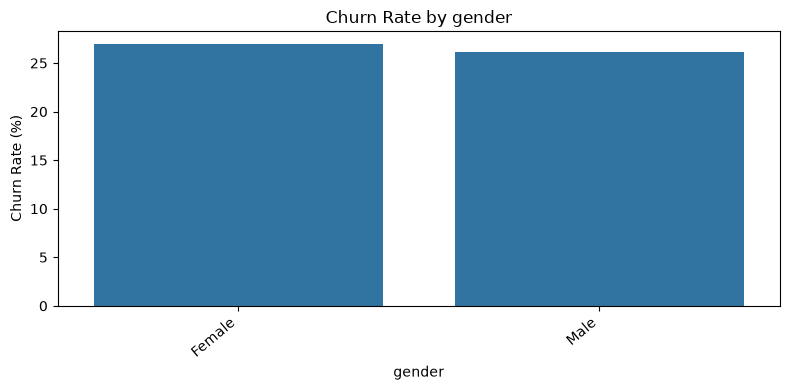

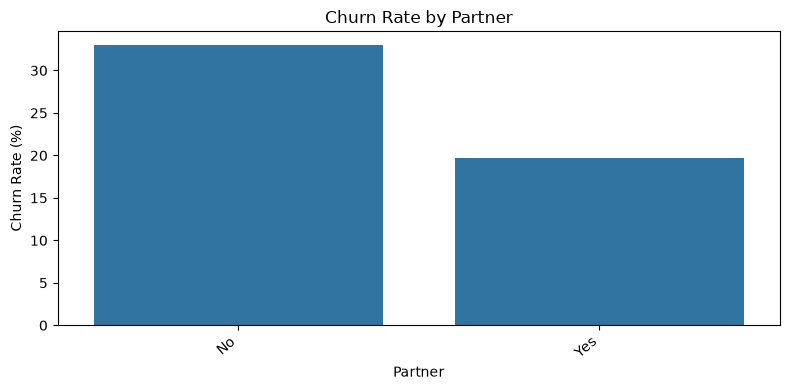

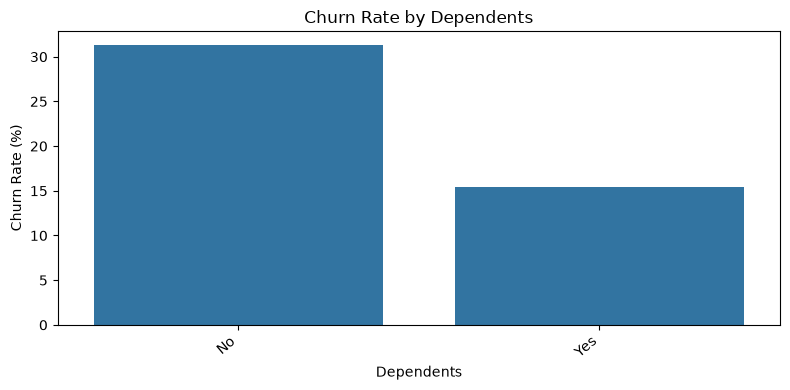

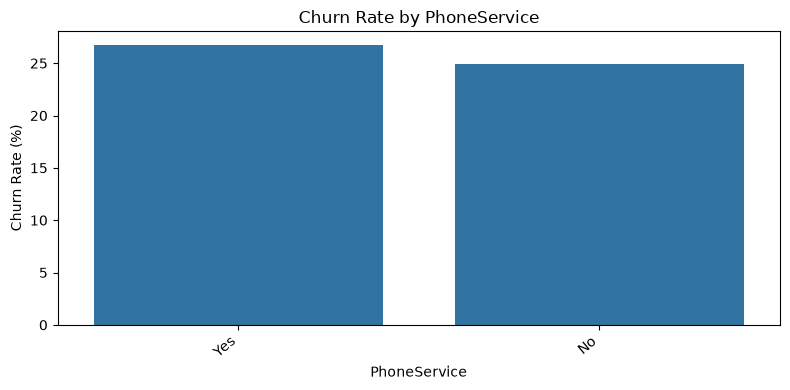

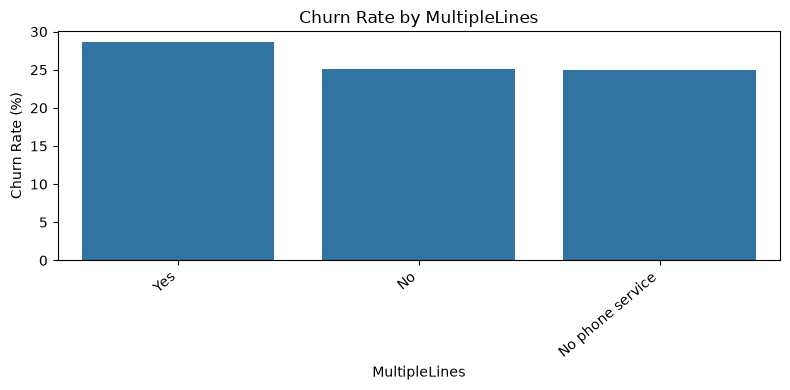

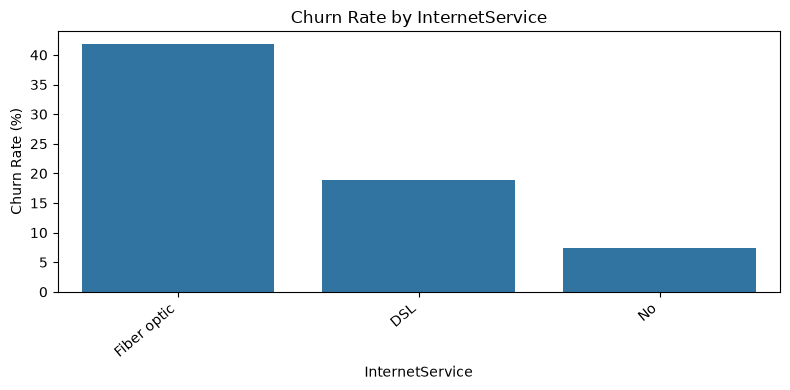

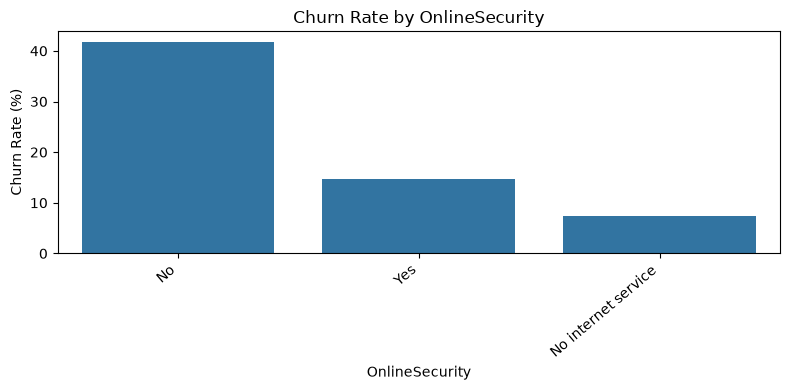

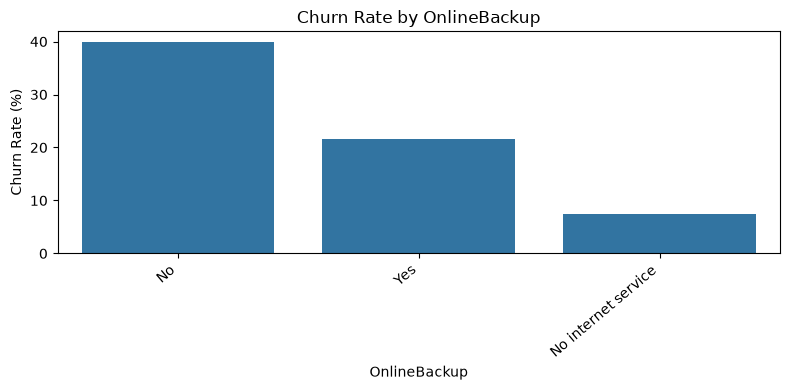

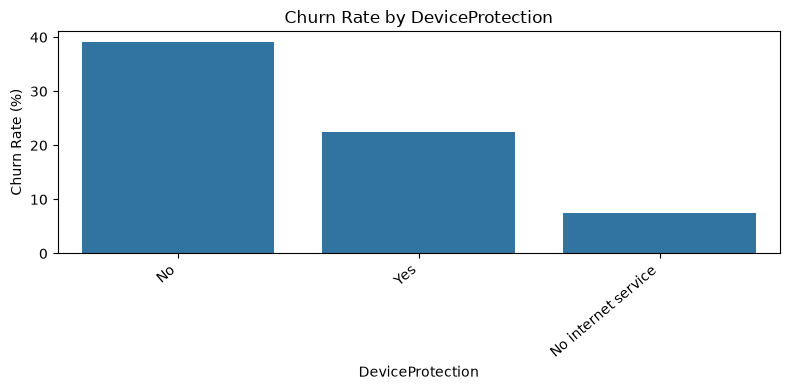

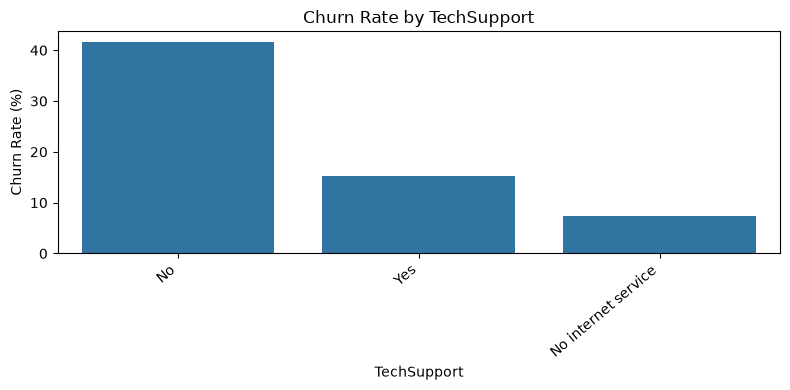

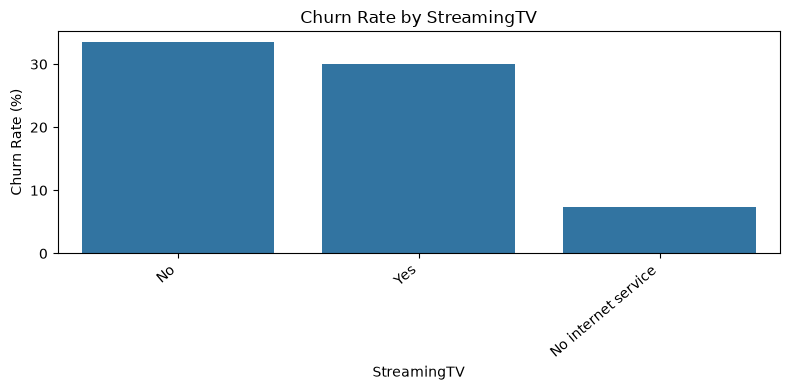

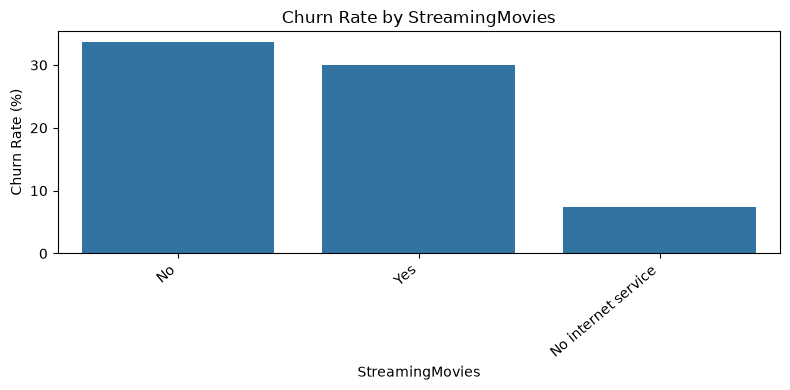

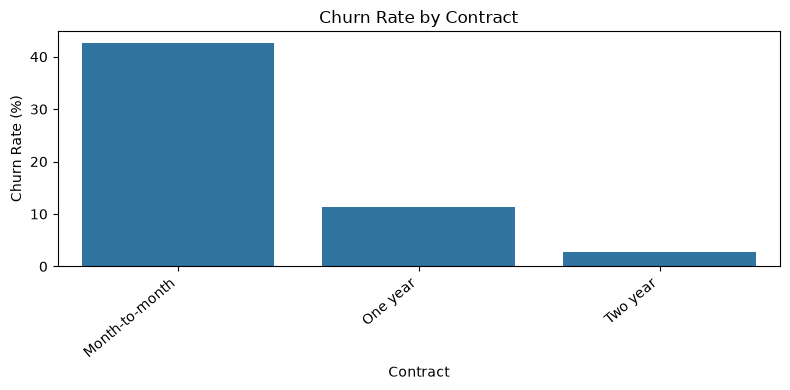

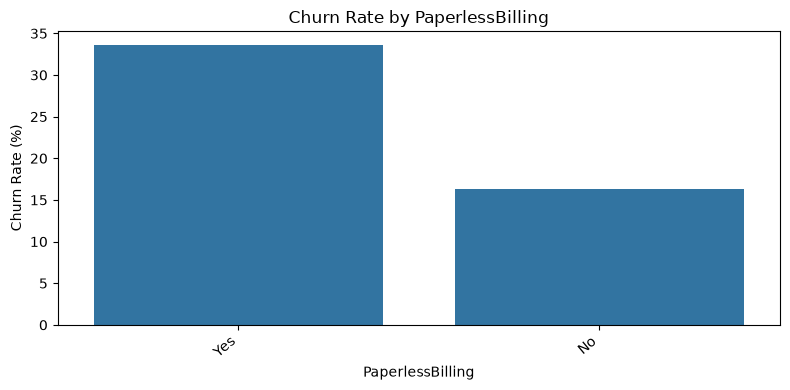

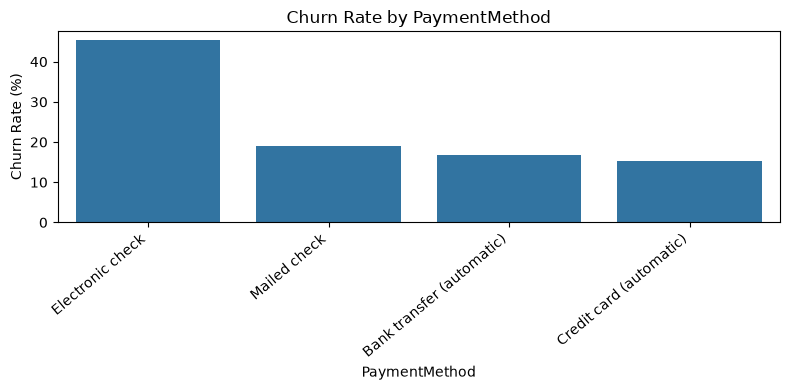

In [41]:
for col in categorical_features:

    churn_rate = (
        df_clean.groupby(col, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values
    )

    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

In [42]:
pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [43]:
categorical_features = [
    col for col in categorical_cols
    if col not in ["customerID", "Churn"]
]

for col in categorical_features:

    print(f"\nFeature: {col}")

    churn_distribution = pd.crosstab(
        df_clean[col],
        df_clean["Churn"],
        normalize="index"
    ) * 100

    print(churn_distribution.round(2))


Feature: gender
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

Feature: Partner
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

Feature: Dependents
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

Feature: PhoneService
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

Feature: MultipleLines
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

Feature: InternetService
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

Feature: OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.3

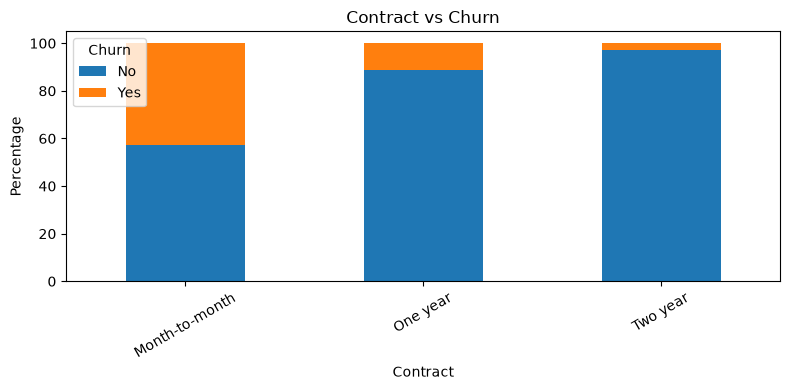

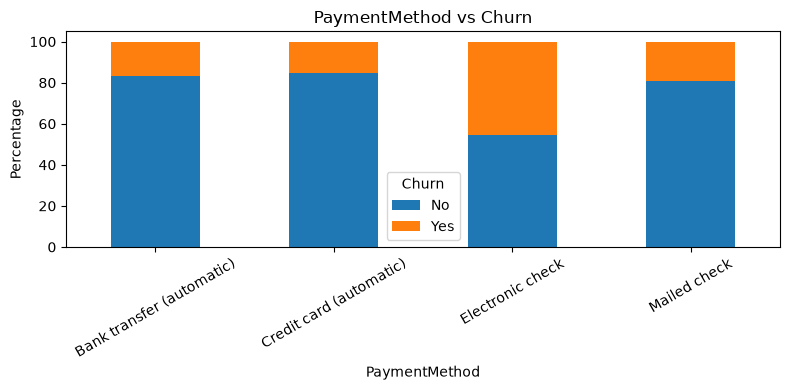

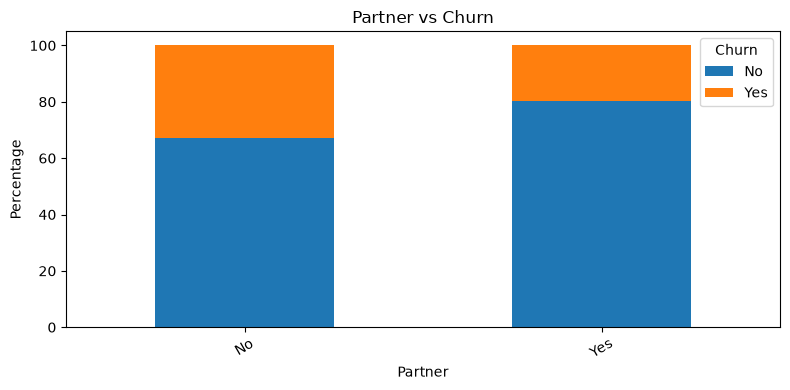

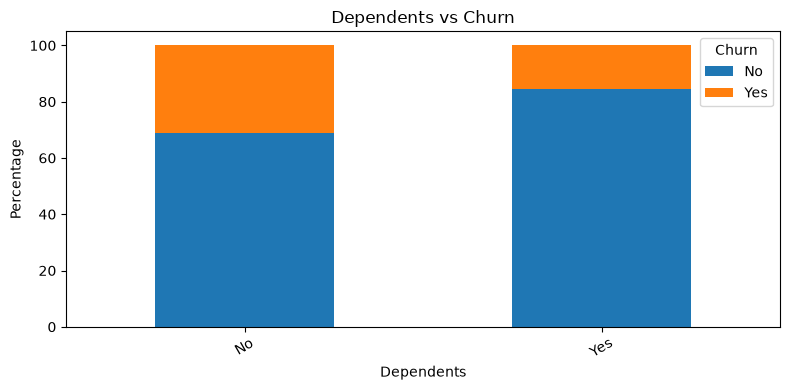

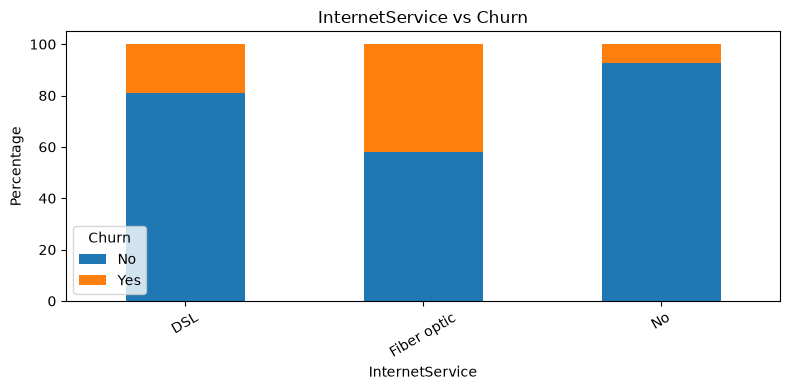

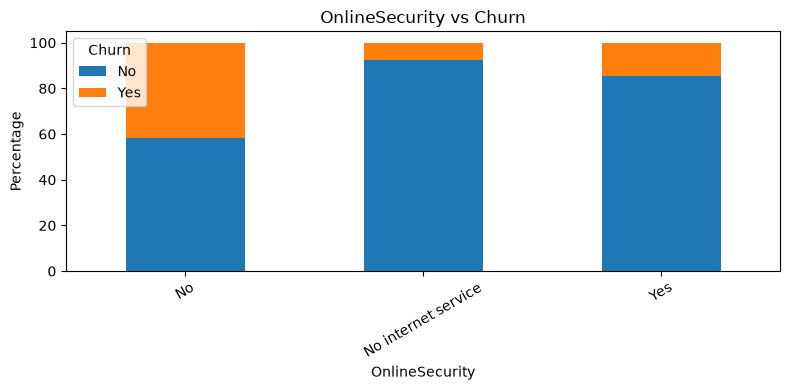

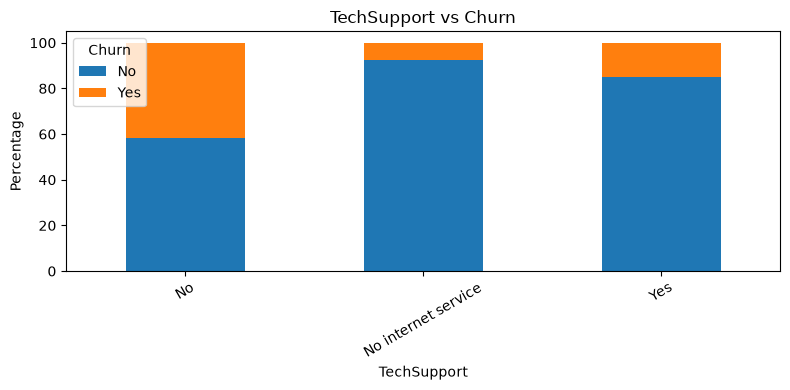

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

features_to_plot = [
    "Contract",
    "PaymentMethod",
    "Partner",
    "Dependents",
    "InternetService",
    "OnlineSecurity",
    "TechSupport"
]

for col in features_to_plot:

    churn_rate = pd.crosstab(
        df_clean[col],
        df_clean["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )

    plt.title(f"{col} vs Churn")
    plt.ylabel("Percentage")
    plt.xlabel(col)
    plt.xticks(rotation=30)
    plt.legend(title="Churn")
    plt.tight_layout()
    plt.show()

In [45]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation_matrix = df_clean[numerical_features].corr()

correlation_matrix

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


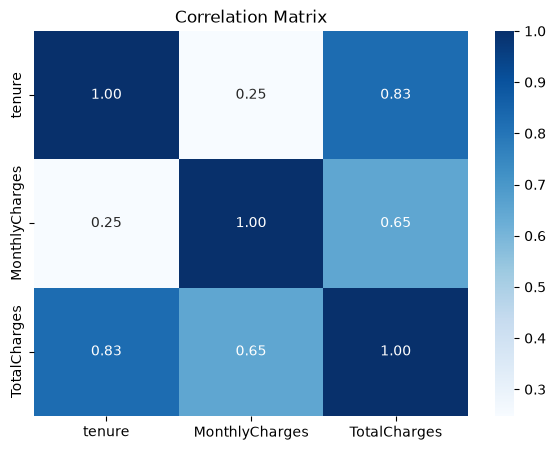

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

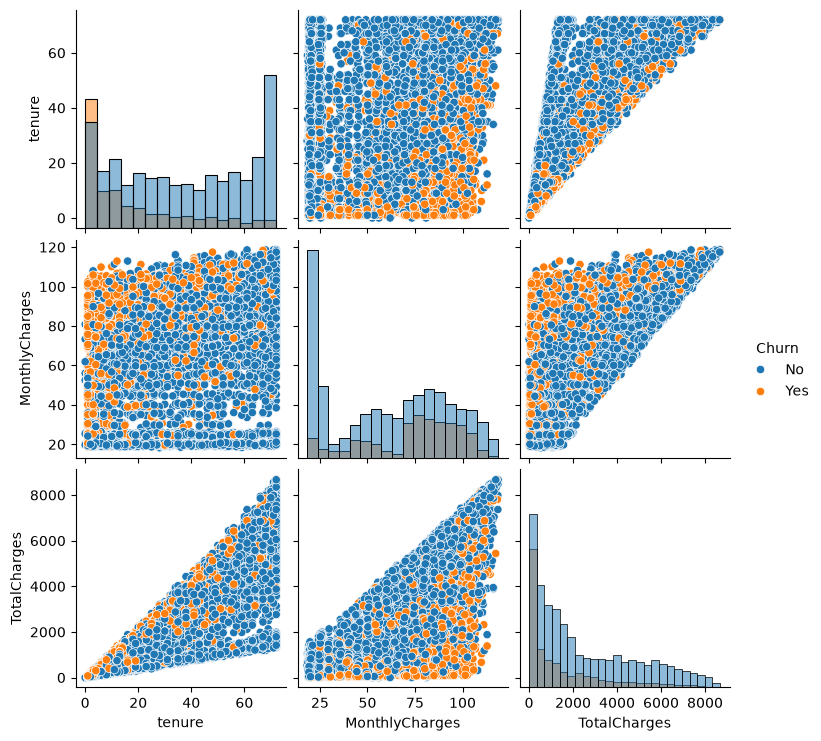

In [50]:
sns.pairplot(
    df_clean,
    vars=numerical_features,
    hue="Churn",
    diag_kind="hist"
)

plt.show()

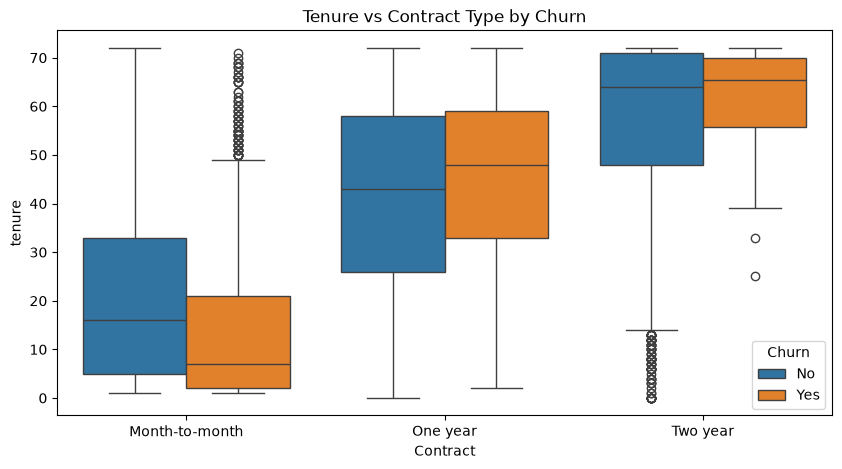

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="Contract",
    y="tenure",
    hue="Churn"
)

plt.title("Tenure vs Contract Type by Churn")
plt.show()

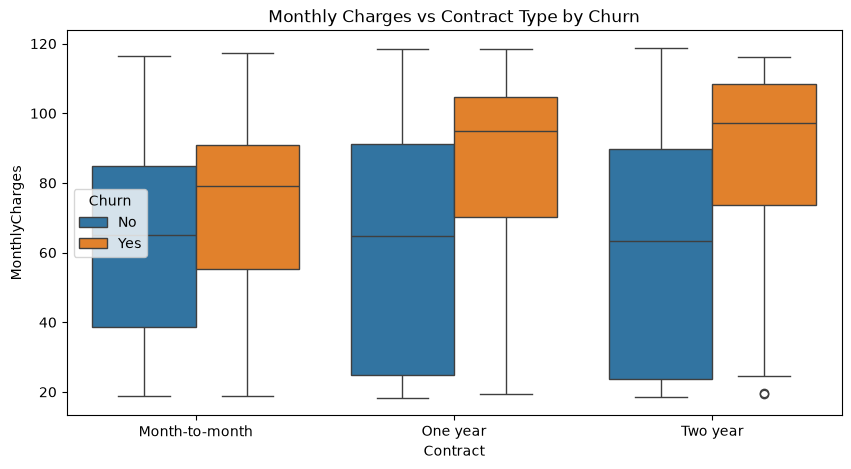

In [52]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="Contract",
    y="MonthlyCharges",
    hue="Churn"
)

plt.title("Monthly Charges vs Contract Type by Churn")
plt.show()

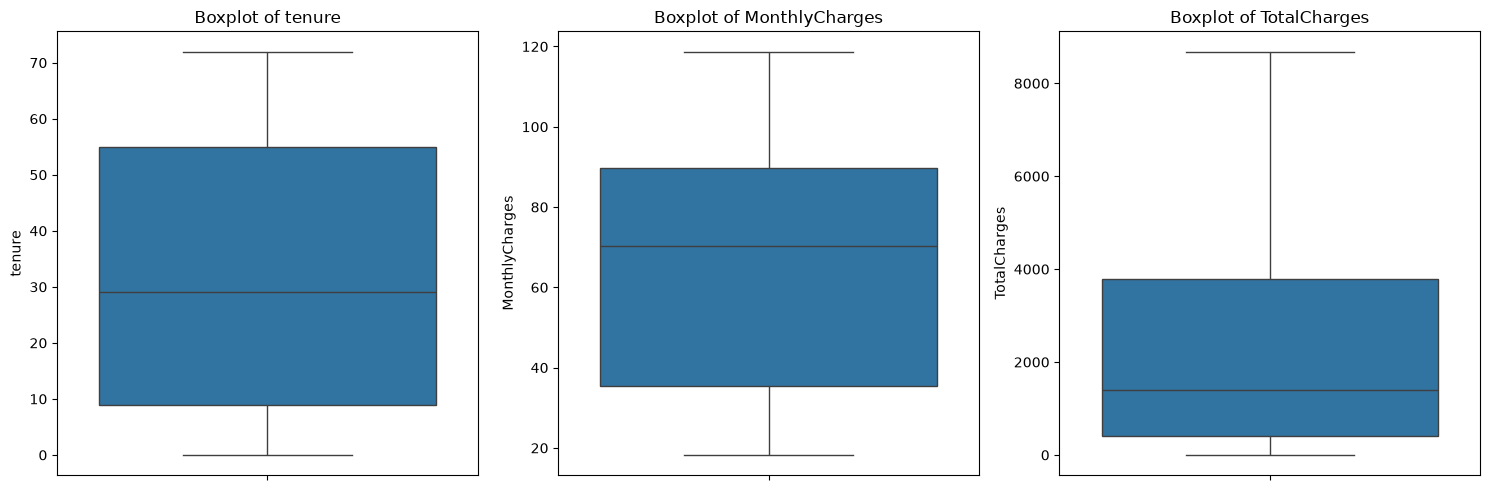


Feature: tenure
Lower Bound: -60.0
Upper Bound: 124.0
Outlier Count: 0
Outlier Percentage: 0.0

Feature: MonthlyCharges
Lower Bound: -46.02499999999999
Upper Bound: 171.375
Outlier Count: 0
Outlier Percentage: 0.0

Feature: TotalCharges
Lower Bound: -4683.525
Upper Bound: 8868.675
Outlier Count: 0
Outlier Percentage: 0.0


In [53]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]


import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(numerical_features):
    sns.boxplot(
        y=df_clean[col],
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


for col in numerical_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"\nFeature: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))
    print("Outlier Percentage:", round(len(outliers) / len(df_clean) * 100, 2))

tenure: 0.240
MonthlyCharges: -0.221
TotalCharges: 0.963


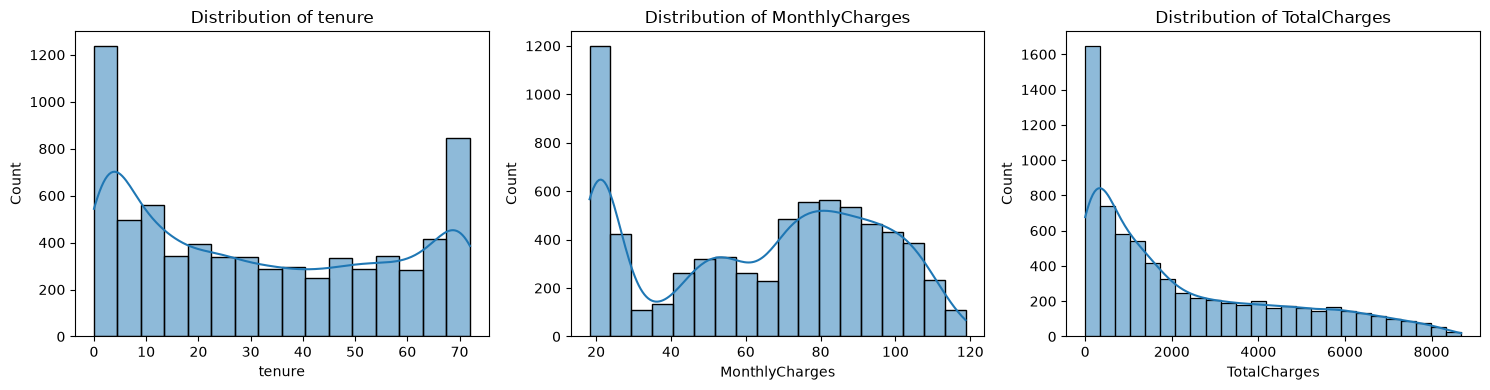

In [54]:
for col in numerical_features:
    print(
        f"{col}: {df_clean[col].skew():.3f}"
    )


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(numerical_features):
    sns.histplot(
        data=df_clean,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()




In [55]:
for col in numerical_features:
    print(f"{col}: {df_clean[col].skew():.3f}")

tenure: 0.240
MonthlyCharges: -0.221
TotalCharges: 0.963


In [56]:
import numpy as np

df_clean["TotalCharges_log"] = np.log1p(
    df_clean["TotalCharges"]
)

print(df_clean["TotalCharges_log"].skew())

-0.8244577693814918


In [57]:
import numpy as np

bins = [0, 12, 24, 36, 48, 72]

labels = [
    "New",
    "Early",
    "Developing",
    "Established",
    "Loyal"
]

df_clean["TenureGroup"] = pd.cut(
    df_clean["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [58]:
df_clean["TenureGroup"].value_counts().sort_index()

TenureGroup
New            2186
Early          1024
Developing      832
Established     762
Loyal          2239
Name: count, dtype: int64

In [59]:
pd.crosstab(
    df_clean["TenureGroup"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
TenureGroup,,
New,52.56,47.44
Early,71.29,28.71
Developing,78.37,21.63
Established,80.97,19.03
Loyal,90.49,9.51


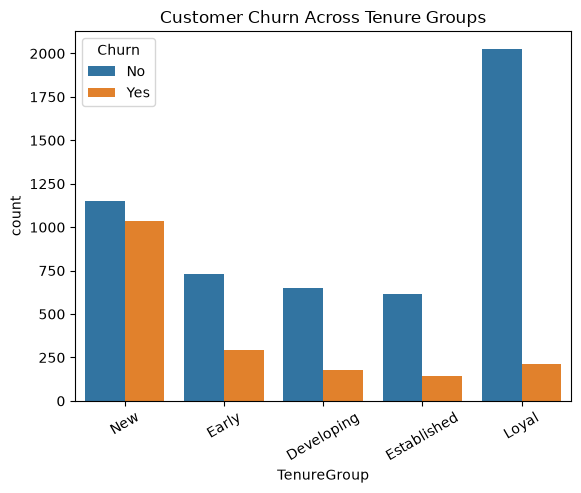

In [60]:
sns.countplot(
    data=df_clean,
    x="TenureGroup",
    hue="Churn"
)

plt.title("Customer Churn Across Tenure Groups")
plt.xticks(rotation=30)
plt.show()

In [61]:
df_clean["AverageMonthlySpend"] = np.where(
    df_clean["tenure"] > 0,
    df_clean["TotalCharges"] / df_clean["tenure"],
    0
)

In [62]:
df_clean["AverageMonthlySpend"].describe()

count    7043.000000
mean       64.698218
std        30.270670
min         0.000000
25%        35.649000
50%        70.300000
75%        90.174158
max       121.400000
Name: AverageMonthlySpend, dtype: float64

In [63]:
df_clean.groupby("Churn")["AverageMonthlySpend"].agg(
    ["mean", "median", "std"]
)

,mean,median,std
Churn,,,
No,61.181674,63.909219,31.237429
Yes,74.433154,79.312500,24.961209


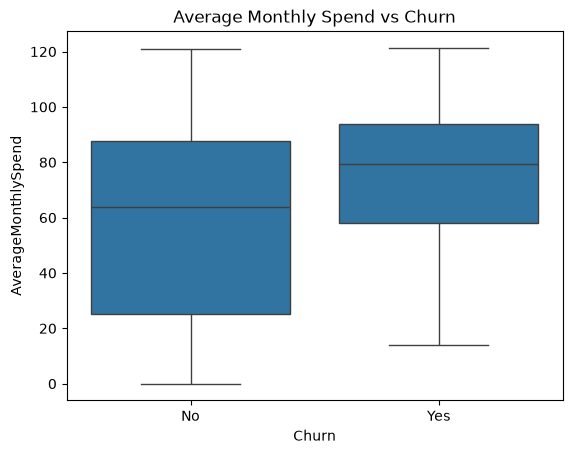

In [64]:
sns.boxplot(
    data=df_clean,
    x="Churn",
    y="AverageMonthlySpend"
)

plt.title("Average Monthly Spend vs Churn")
plt.show()

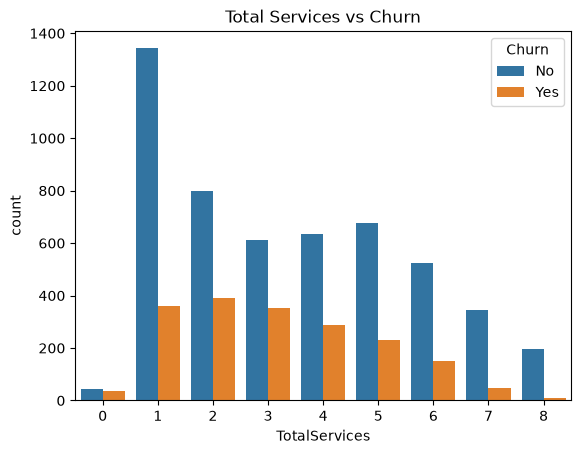

In [66]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df_clean["TotalServices"] = (
    df_clean[service_columns] == "Yes"
).sum(axis=1)

df_clean["TotalServices"].value_counts().sort_index()

pd.crosstab(
    df_clean["TotalServices"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)

sns.countplot(
    data=df_clean,
    x="TotalServices",
    hue="Churn"
)

plt.title("Total Services vs Churn")
plt.show()

In [67]:
df_clean["IsLongTermContract"] = (
    df_clean["Contract"] != "Month-to-month"
).astype(int)

df_clean["IsLongTermContract"].value_counts()


pd.crosstab(
    df_clean["IsLongTermContract"],
    df_clean["Churn"],
    normalize="index"
).mul(100).round(2)



Churn,No,Yes
IsLongTermContract,,
0,57.29,42.71
1,93.24,6.76


In [68]:
print("Dataset Shape:", df_clean.shape)

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Dataset Shape: (7043, 26)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TotalCharges_log', 'TenureGroup', 'AverageMonthlySpend', 'TotalServices', 'IsLongTermContract']

Missing Values:
customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection       0
TechSupport            0
StreamingTV            0
StreamingMovies        0
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                

In [69]:
df_clean.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_log,TenureGroup,AverageMonthlySpend,TotalServices,IsLongTermContract
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,Yes,Electronic check,29.85,29.85,No,3.429137,New,29.850000,1,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,Mailed check,56.95,1889.50,No,7.544597,Developing,55.573529,3,1
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,Yes,Mailed check,53.85,108.15,Yes,4.692723,New,54.075000,3,0
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,Bank transfer (automatic),42.30,1840.75,No,7.518471,Established,40.905556,3,1
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,Yes,Electronic check,70.70,151.65,Yes,5.028148,New,75.825000,1,0


In [70]:
X = df_clean.drop(
    columns=[
        "customerID",
        "Churn",
        "TotalCharges_log",
        "TenureGroup",
        "AverageMonthlySpend",
        "TotalServices",
        "IsLongTermContract"
    ]
)

y = df_clean["Churn"]

In [71]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [72]:
numerical_features.remove("SeniorCitizen")
categorical_features.append("SeniorCitizen")

In [73]:
print("Numerical Count:", len(numerical_features))
print("Categorical Count:", len(categorical_features))
print("Total Features:", len(numerical_features) + len(categorical_features))

Numerical Count: 3
Categorical Count: 16
Total Features: 19


In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

X_train: (5634, 19)
X_test: (1409, 19)

Training Target Distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


In [75]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (5634, 46)
Testing Shape: (1409, 46)


In [76]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_pipeline.fit(X_train, y_train)

y_pred = logistic_pipeline.predict(X_test)
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, pos_label="Yes"
))
print("Recall:", recall_score(
    y_test, y_pred, pos_label="Yes"
))
print("F1 Score:", f1_score(
    y_test, y_pred, pos_label="Yes"
))
print("ROC-AUC:", roc_auc_score(
    y_test,
    y_prob,
    labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664
ROC-AUC: 0.8420341522643313

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]


In [78]:
baseline_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.8055,
        "Precision": 0.6572,
        "Recall": 0.5588,
        "F1 Score": 0.6040,
        "ROC-AUC": 0.8420
    }
])

baseline_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.604,0.842


In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [80]:
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [81]:
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(
    y_test, rf_pred, pos_label="Yes"
))
print("Recall:", recall_score(
    y_test, rf_pred, pos_label="Yes"
))
print("F1 Score:", f1_score(
    y_test, rf_pred, pos_label="Yes"
))
print("ROC-AUC:", roc_auc_score(
    y_test,
    rf_prob,
    labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    rf_pred,
    labels=["No", "Yes"]
))

Accuracy: 0.7927608232789212
Precision: 0.6404109589041096
Recall: 0.5
F1 Score: 0.5615615615615616
ROC-AUC: 0.8237399571159163

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409


Confusion Matrix:
[[930 105]
 [187 187]]


In [83]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]
)

gb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [84]:
gb_pred = gb_pipeline.predict(X_test)

gb_prob = gb_pipeline.predict_proba(X_test)[:, 1]

In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, gb_pred))

print("Precision:", precision_score(
    y_test, gb_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, gb_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, gb_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, gb_prob,
    labels=["No", "Yes"]
))

Accuracy: 0.8026969481902059
Precision: 0.6655172413793103
Recall: 0.516042780748663
F1 Score: 0.5813253012048193
ROC-AUC: 0.8433452168746287


In [86]:
uv add xgboost

Note: you may need to restart the kernel to use updated packages.


d:\MLProjects\Telecom Churn Prediction\.venv\Scripts\python.exe: No module named uv


In [87]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [90]:
y_train_xgb = y_train.map({
    "No": 0,
    "Yes": 1
})

y_test_xgb = y_test.map({
    "No": 0,
    "Yes": 1
})

In [91]:
xgb_pipeline.fit(X_train, y_train_xgb)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [92]:
xgb_pred = xgb_pipeline.predict(X_test)
xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

In [93]:
print("Accuracy:", accuracy_score(y_test_xgb, xgb_pred))

print("Precision:", precision_score(
    y_test_xgb, xgb_pred, pos_label=1
))

print("Recall:", recall_score(
    y_test_xgb, xgb_pred, pos_label=1
))

print("F1 Score:", f1_score(
    y_test_xgb, xgb_pred, pos_label=1
))

print("ROC-AUC:", roc_auc_score(
    y_test_xgb, xgb_prob
))

Accuracy: 0.7984386089425124
Precision: 0.65
Recall: 0.5213903743315508
F1 Score: 0.5786350148367952
ROC-AUC: 0.8430106693533803


In [94]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

lgbm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LGBMClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            num_leaves=15,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ]
)

In [95]:
lgbm_pipeline.fit(X_train, y_train_xgb)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [96]:
lgbm_pred = lgbm_pipeline.predict(X_test)

lgbm_prob = lgbm_pipeline.predict_proba(X_test)[:, 1]

In [97]:
print("Accuracy:", accuracy_score(y_test_xgb, lgbm_pred))

print("Precision:", precision_score(
    y_test_xgb, lgbm_pred, pos_label=1
))

print("Recall:", recall_score(
    y_test_xgb, lgbm_pred, pos_label=1
))

print("F1 Score:", f1_score(
    y_test_xgb, lgbm_pred, pos_label=1
))

print("ROC-AUC:", roc_auc_score(
    y_test_xgb, lgbm_prob
))

Accuracy: 0.8034066713981547
Precision: 0.6632996632996633
Recall: 0.5267379679144385
F1 Score: 0.587183308494784
ROC-AUC: 0.843381384174223


In [100]:
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline

catboost_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", CatBoostClassifier(
            iterations=300,
            learning_rate=0.05,
            depth=5,
            loss_function="Logloss",
            eval_metric="AUC",
            random_seed=42,
            verbose=0,
            thread_count=-1
        ))
    ]
)

In [101]:
catboost_pipeline.fit(X_train, y_train_xgb)

catboost_pred = catboost_pipeline.predict(X_test)
catboost_prob = catboost_pipeline.predict_proba(X_test)[:, 1]

In [102]:
print("Accuracy:", accuracy_score(y_test_xgb, catboost_pred))

print("Precision:", precision_score(
    y_test_xgb, catboost_pred
))

print("Recall:", recall_score(
    y_test_xgb, catboost_pred
))

print("F1 Score:", f1_score(
    y_test_xgb, catboost_pred
))

print("ROC-AUC:", roc_auc_score(
    y_test_xgb, catboost_prob
))

Accuracy: 0.8034066713981547
Precision: 0.659016393442623
Recall: 0.5374331550802139
F1 Score: 0.5920471281296024
ROC-AUC: 0.84440827714485


In [103]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            probability=True,
            random_state=42
        ))
    ]
)

In [105]:
svm_pipeline.fit(X_train, y_train)

svm_pred = svm_pipeline.predict(X_test)
svm_prob = svm_pipeline.predict_proba(X_test)[:, 1]

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [106]:
print("Accuracy:", accuracy_score(y_test, svm_pred))

print("Precision:", precision_score(
    y_test, svm_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, svm_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, svm_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, svm_prob, labels=["No", "Yes"]
))

Accuracy: 0.7899219304471257
Precision: 0.6373239436619719
Recall: 0.4839572192513369
F1 Score: 0.5501519756838906
ROC-AUC: 0.7927846237309153


In [107]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            weights="uniform",
            metric="minkowski",
            p=2,
            n_jobs=-1
        ))
    ]
)

In [108]:
knn_pipeline.fit(X_train, y_train)

knn_pred = knn_pipeline.predict(X_test)
knn_prob = knn_pipeline.predict_proba(X_test)[:, 1]

In [109]:
print("Accuracy:", accuracy_score(y_test, knn_pred))

print("Precision:", precision_score(
    y_test, knn_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, knn_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, knn_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, knn_prob, labels=["No", "Yes"]
))

Accuracy: 0.7572746628814763
Precision: 0.5418848167539267
Recall: 0.553475935828877
F1 Score: 0.5476190476190477
ROC-AUC: 0.788166834586272


In [110]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            criterion="gini",
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=42
        ))
    ]
)

In [111]:
dt_pipeline.fit(X_train, y_train)

dt_pred = dt_pipeline.predict(X_test)
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]

In [112]:
print("Accuracy:", accuracy_score(y_test, dt_pred))

print("Precision:", precision_score(
    y_test, dt_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, dt_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, dt_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, dt_prob, labels=["No", "Yes"]
))

Accuracy: 0.7984386089425124
Precision: 0.6347305389221557
Recall: 0.5668449197860963
F1 Score: 0.5988700564971752
ROC-AUC: 0.8274948978273786


In [113]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

nb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GaussianNB())
    ]
)

In [114]:
nb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U3](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [115]:
nb_pred = nb_pipeline.predict(X_test)
nb_prob = nb_pipeline.predict_proba(X_test)[:, 1]

In [117]:
print("Accuracy:", accuracy_score(y_test, nb_pred))

print("Precision:", precision_score(
    y_test, nb_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, nb_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, nb_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, nb_prob, labels=["No", "Yes"]
))

print("confusion_matrix: ", confusion_matrix(y_test, nb_pred, labels=["No", "Yes"]))

Accuracy: 0.6955287437899219
Precision: 0.45973645680819913
Recall: 0.839572192513369
F1 Score: 0.5941343424787133
ROC-AUC: 0.8075021312872976
confusion_matrix:  [[666 369]
 [ 60 314]]


In [118]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

accuracy: Mean = 0.8019, Std = 0.0118
precision: Mean = nan, Std = nan
recall: Mean = nan, Std = nan
f1: Mean = nan, Std = nan
roc_auc: Mean = 0.8461, Std = 0.0126


In [119]:
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

scoring = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        pos_label="Yes"
    ),

    "recall": make_scorer(
        recall_score,
        pos_label="Yes"
    ),

    "f1": make_scorer(
        f1_score,
        pos_label="Yes"
    ),

    "roc_auc": "roc_auc"
}

In [120]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"Mean = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

accuracy: Mean = 0.8019, Std = 0.0118
precision: Mean = 0.6521, Std = 0.0256
recall: Mean = 0.5438, Std = 0.0409
f1: Mean = 0.5924, Std = 0.0298
roc_auc: Mean = 0.8461, Std = 0.0126


In [121]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Gradient Boosting": gb_pipeline,
    "XGBoost": xgb_pipeline,
    "LightGBM": lgbm_pipeline,
    "CatBoost": catboost_pipeline,
    "Decision Tree": dt_pipeline
}

In [122]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

cv_summary = []

for name, pipeline in models.items():

    print(f"Evaluating: {name}")

    model = clone(pipeline)

    results = cross_validate(
        model,
        X_train,
        y_train_xgb,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=1
    )

    cv_summary.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean(),
        "Accuracy_Std": results["test_accuracy"].std(),
        "Recall_Std": results["test_recall"].std()
    })

cv_results_df = pd.DataFrame(cv_summary)

cv_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

Evaluating: Logistic Regression
Evaluating: Gradient Boosting
Evaluating: XGBoost
Evaluating: LightGBM
Evaluating: CatBoost
Evaluating: Decision Tree


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_Std,Recall_Std
1,Gradient Boosting,0.803340,0.662221,0.529097,0.587972,0.848112,0.013546,0.030462
3,LightGBM,0.803339,0.662791,0.527090,0.586986,0.847317,0.011638,0.029126
2,XGBoost,0.804936,0.665898,0.533110,0.591706,0.847290,0.010752,0.028894
4,CatBoost,0.804048,0.666813,0.523077,0.585947,0.846918,0.013393,0.033418
0,Logistic Regression,0.801918,0.652094,0.543813,0.592412,0.846149,0.011767,0.040885
5,Decision Tree,0.790915,0.632209,0.513712,0.564706,0.828575,0.009433,0.051838


In [123]:
from sklearn.ensemble import VotingClassifier

voting_pipeline = VotingClassifier(
    estimators=[
        ("nb", nb_pipeline),
        ("lr", logistic_pipeline),
        ("gb", gb_pipeline)
    ],
    voting="soft",
    weights=[1, 1, 1],
    n_jobs=1
)

voting_pipeline.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('lr', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.","[1, 1, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",1
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['No','Yes']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step...aussianNB())]), Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [124]:
voting_pred = voting_pipeline.predict(X_test)

voting_prob = voting_pipeline.predict_proba(X_test)[:, 1]

In [125]:
print("Accuracy:", accuracy_score(y_test, voting_pred))

print("Precision:", precision_score(
    y_test, voting_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, voting_pred, pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test, voting_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, voting_prob, labels=["No", "Yes"]
))

Accuracy: 0.751596877217885
Precision: 0.521505376344086
Recall: 0.7780748663101604
F1 Score: 0.6244635193133047
ROC-AUC: 0.8412668888372214


In [126]:
from sklearn.ensemble import VotingClassifier

hard_voting_pipeline = VotingClassifier(
    estimators=[
        ("nb", nb_pipeline),
        ("lr", logistic_pipeline),
        ("gb", gb_pipeline)
    ],
    voting="hard",
    n_jobs=1
)

hard_voting_pipeline.fit(X_train, y_train)

hard_pred = hard_voting_pipeline.predict(X_test)

In [127]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, hard_pred))
print("Precision:", precision_score(y_test, hard_pred, pos_label="Yes"))
print("Recall:", recall_score(y_test, hard_pred, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, hard_pred, pos_label="Yes"))

print("Confusion Matrix:")
print(confusion_matrix(y_test, hard_pred, labels=["No", "Yes"]))

Accuracy: 0.8048261178140526
Precision: 0.6418338108882522
Recall: 0.5989304812834224
F1 Score: 0.6196403872752421
Confusion Matrix:
[[910 125]
 [150 224]]


In [128]:
weighted_voting_pipeline = VotingClassifier(
    estimators=[
        ("nb", nb_pipeline),
        ("lr", logistic_pipeline),
        ("gb", gb_pipeline)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=1
)

weighted_voting_pipeline.fit(X_train, y_train)

weighted_pred = weighted_voting_pipeline.predict(X_test)

yes_idx = list(weighted_voting_pipeline.classes_).index("Yes")
weighted_prob = weighted_voting_pipeline.predict_proba(X_test)[:, yes_idx]

In [129]:
print("Accuracy:", accuracy_score(y_test, weighted_pred))
print("Precision:", precision_score(y_test, weighted_pred, pos_label="Yes"))
print("Recall:", recall_score(y_test, weighted_pred, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, weighted_pred, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(
    (y_test == "Yes").astype(int),
    weighted_prob
))

Accuracy: 0.7068843151171044
Precision: 0.4700460829493088
Recall: 0.8181818181818182
F1 Score: 0.5970731707317073
ROC-AUC: 0.8403807899971584


In [131]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score, f1_score
from sklearn.naive_bayes import GaussianNB

nb_param_grid = {
    "model__var_smoothing": [
        1e-12,
        1e-11,
        1e-10,
        1e-9,
        1e-8,
        1e-7,
        1e-6
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Yes"
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Yes"
    ),
    "roc_auc": "roc_auc"
}

nb_grid_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=nb_param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=1,
    verbose=1
)

nb_grid_search.fit(X_train, y_train)

print("Best Parameters:", nb_grid_search.best_params_)
print("Best CV F1:", nb_grid_search.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best Parameters: {'model__var_smoothing': 1e-12}
Best CV F1: 0.5984803756549348


In [132]:
best_nb_index = nb_grid_search.best_index_

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    score = nb_grid_search.cv_results_[
        f"mean_test_{metric}"
    ][best_nb_index]

    print(f"{metric}: {score:.4f}")

accuracy: 0.6990
precision: 0.4633
recall: 0.8455
f1: 0.5985
roc_auc: 0.8199


In [134]:
best_nb_pipeline = nb_grid_search.best_estimator_

In [135]:
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
    "model__solver": ["liblinear"],
    "model__class_weight": [None, "balanced"]
}

lr_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=lr_param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=1,
    verbose=1
)

lr_grid_search.fit(X_train, y_train)

print("Best Parameters:", lr_grid_search.best_params_)
print("Best CV F1:", lr_grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' 

Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'model__solver': 'liblinear'}
Best CV F1: 0.6294733251869348


d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [136]:
LogisticRegression(
    C=0.1,
    solver="liblinear",
    l1_ratio=0
)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [137]:
best_lr_index = lr_grid_search.best_index_

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    score = lr_grid_search.cv_results_[
        f"mean_test_{metric}"
    ][best_lr_index]

    print(f"{metric}: {score:.4f}")

accuracy: 0.7508
precision: 0.5199
recall: 0.7980
f1: 0.6295
roc_auc: 0.8455


In [138]:
best_lr_pipeline = lr_grid_search.best_estimator_

In [140]:
gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__subsample": [0.8, 1.0]
}

gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

print("Best Parameters:", gb_grid_search.best_params_)
print("Best CV F1:", gb_grid_search.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV F1: 0.5951697342581752


In [141]:
best_gb_pipeline = gb_grid_search.best_estimator_

In [142]:
best_gb_index = gb_grid_search.best_index_

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    score = gb_grid_search.cv_results_[
        f"mean_test_{metric}"
    ][best_gb_index]

    print(f"{metric}: {score:.4f}")

accuracy: 0.8078
precision: 0.6744
recall: 0.5331
f1: 0.5952
roc_auc: 0.8505


In [143]:
best_gb_pipeline = gb_grid_search.best_estimator_

In [144]:
from sklearn.ensemble import VotingClassifier

tuned_soft_voting = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="soft",
    n_jobs=1
)

tuned_soft_voting.fit(X_train, y_train)

tuned_soft_pred = tuned_soft_voting.predict(X_test)

yes_idx = list(tuned_soft_voting.classes_).index("Yes")

tuned_soft_prob = tuned_soft_voting.predict_proba(X_test)[:, yes_idx]

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [145]:
print("Accuracy:", accuracy_score(y_test, tuned_soft_pred))
print("Precision:", precision_score(y_test, tuned_soft_pred, pos_label="Yes"))
print("Recall:", recall_score(y_test, tuned_soft_pred, pos_label="Yes"))
print("F1:", f1_score(y_test, tuned_soft_pred, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(
    (y_test == "Yes").astype(int),
    tuned_soft_prob
))

Accuracy: 0.7203690560681334
Precision: 0.4840764331210191
Recall: 0.8128342245989305
F1: 0.6067864271457086
ROC-AUC: 0.8419669844222273


In [146]:
tuned_hard_voting = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="hard",
    n_jobs=1
)

tuned_hard_voting.fit(X_train, y_train)

tuned_hard_pred = tuned_hard_voting.predict(X_test)

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [147]:
print("Accuracy:", accuracy_score(y_test, tuned_hard_pred))

print("Precision:", precision_score(
    y_test, tuned_hard_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, tuned_hard_pred, pos_label="Yes"
))

print("F1:", f1_score(
    y_test, tuned_hard_pred, pos_label="Yes"
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, tuned_hard_pred, labels=["No", "Yes"]
))

Accuracy: 0.7466288147622427
Precision: 0.5149384885764499
Recall: 0.7834224598930482
F1: 0.6214209968186638
Confusion Matrix:
[[759 276]
 [ 81 293]]


In [148]:
tuned_weighted_voting = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=1
)

tuned_weighted_voting.fit(X_train, y_train)

tuned_weighted_pred = tuned_weighted_voting.predict(X_test)

yes_idx = list(tuned_weighted_voting.classes_).index("Yes")

tuned_weighted_prob = (
    tuned_weighted_voting.predict_proba(X_test)[:, yes_idx]
)

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [149]:
print("Accuracy:", accuracy_score(y_test, tuned_weighted_pred))

print("Precision:", precision_score(
    y_test, tuned_weighted_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, tuned_weighted_pred, pos_label="Yes"
))

print("F1:", f1_score(
    y_test, tuned_weighted_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    (y_test == "Yes").astype(int),
    tuned_weighted_prob
))

Accuracy: 0.6983676366217175
Precision: 0.46153846153846156
Recall: 0.8181818181818182
F1: 0.5901639344262295
ROC-AUC: 0.8411222196388437


In [150]:
from sklearn.model_selection import cross_validate

ensemble_cv = {
    "soft": VotingClassifier(
        estimators=[
            ("nb", best_nb_pipeline),
            ("lr", best_lr_pipeline),
            ("gb", best_gb_pipeline)
        ],
        voting="soft",
        n_jobs=1
    ),

    "hard": VotingClassifier(
        estimators=[
            ("nb", best_nb_pipeline),
            ("lr", best_lr_pipeline),
            ("gb", best_gb_pipeline)
        ],
        voting="hard",
        n_jobs=1
    ),

    "weighted_soft": VotingClassifier(
        estimators=[
            ("nb", best_nb_pipeline),
            ("lr", best_lr_pipeline),
            ("gb", best_gb_pipeline)
        ],
        voting="soft",
        weights=[2, 1, 1],
        n_jobs=1
    )
}

In [152]:
soft_scoring = scoring.copy()

hard_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes"
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score, pos_label="Yes"
    )
}

In [154]:
ensemble_results = {}

for name, model in ensemble_cv.items():

    if name == "hard":
        selected_scoring = hard_scoring
    else:
        selected_scoring = soft_scoring

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=selected_scoring,
        n_jobs=1
    )

    ensemble_results[name] = {
        metric: scores[f"test_{metric}"].mean()
        for metric in selected_scoring
    }

ensemble_comparison = pd.DataFrame(
    ensemble_results
).T

print(ensemble_comparison.round(4))

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Teleco

               accuracy  precision  recall      f1  roc_auc
soft             0.7260     0.4906  0.8221  0.6142   0.8465
hard             0.7545     0.5249  0.7913  0.6310      NaN
weighted_soft    0.7078     0.4718  0.8381  0.6036   0.8460


In [155]:
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import VotingClassifier

soft_oof_model = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="soft",
    n_jobs=1
)

oof_prob = cross_val_predict(
    soft_oof_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Teleco

In [159]:
oof_prob_yes = oof_prob[:, 1]

In [160]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]:

    predictions = np.where(
        oof_prob_yes >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_train, predictions),
        "precision": precision_score(
            y_train, predictions, pos_label="Yes"
        ),
        "recall": recall_score(
            y_train, predictions, pos_label="Yes"
        ),
        "f1": f1_score(
            y_train, predictions, pos_label="Yes"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   threshold  accuracy  precision  recall      f1
0       0.30    0.6933     0.4583  0.8575  0.5974
1       0.35    0.6990     0.4634  0.8502  0.5998
2       0.40    0.7057     0.4697  0.8441  0.6035
3       0.45    0.7116     0.4752  0.8341  0.6055
4       0.50    0.7259     0.4902  0.8221  0.6142
5       0.55    0.7448     0.5122  0.8033  0.6255
6       0.60    0.7671     0.5436  0.7632  0.6349
7       0.65    0.7874     0.5820  0.7050  0.6376
8       0.70    0.7987     0.6212  0.6187  0.6200


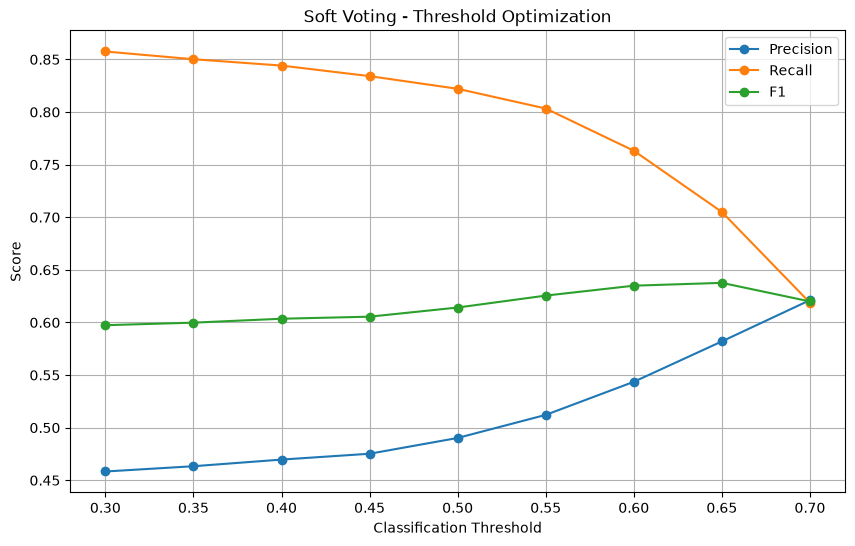

In [161]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Soft Voting - Threshold Optimization")

plt.legend()
plt.grid()
plt.show()

In [162]:
best_soft_threshold = 0.65

In [165]:
weighted_oof_model = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=1
)

weighted_oof_prob = cross_val_predict(
    weighted_oof_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

weighted_oof_prob_yes = weighted_oof_prob[:, 1]

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Teleco

In [166]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]:

    predictions = np.where(
        weighted_oof_prob_yes >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_train, predictions),
        "precision": precision_score(
            y_train, predictions, pos_label="Yes"
        ),
        "recall": recall_score(
            y_train, predictions, pos_label="Yes"
        ),
        "f1": f1_score(
            y_train, predictions, pos_label="Yes"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   threshold  accuracy  precision  recall      f1
0       0.30    0.6926     0.4575  0.8542  0.5959
1       0.35    0.6951     0.4597  0.8502  0.5967
2       0.40    0.6995     0.4637  0.8462  0.5991
3       0.45    0.7032     0.4672  0.8435  0.6013
4       0.50    0.7078     0.4716  0.8381  0.6036
5       0.55    0.7118     0.4754  0.8321  0.6051
6       0.60    0.7206     0.4845  0.8241  0.6102
7       0.65    0.7412     0.5078  0.8074  0.6235
8       0.70    0.7691     0.5466  0.7605  0.6361


In [167]:
from sklearn.model_selection import cross_val_predict

lr_oof_prob = cross_val_predict(
    best_lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

lr_oof_prob_yes = lr_oof_prob[:, 1]

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\MLProjects\Teleco

In [168]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65, 0.70
]:

    predictions = np.where(
        lr_oof_prob_yes >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_train, predictions),
        "precision": precision_score(
            y_train, predictions, pos_label="Yes"
        ),
        "recall": recall_score(
            y_train, predictions, pos_label="Yes"
        ),
        "f1": f1_score(
            y_train, predictions, pos_label="Yes"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   threshold  accuracy  precision  recall      f1
0       0.30    0.6454     0.4230  0.9244  0.5804
1       0.35    0.6786     0.4476  0.9030  0.5985
2       0.40    0.7066     0.4711  0.8629  0.6095
3       0.45    0.7297     0.4944  0.8314  0.6201
4       0.50    0.7508     0.5198  0.7980  0.6296
5       0.55    0.7687     0.5458  0.7645  0.6369
6       0.60    0.7838     0.5747  0.7124  0.6362
7       0.65    0.7932     0.6005  0.6595  0.6286
8       0.70    0.7994     0.6327  0.5819  0.6063


In [169]:
probability_sets = {
    "Logistic Regression": lr_oof_prob_yes,
    "Soft Voting": oof_prob_yes,
    "Weighted Soft Voting": weighted_oof_prob_yes
}

recall_results = []

for model_name, probabilities in probability_sets.items():

    for threshold in np.arange(0.30, 0.71, 0.01):

        predictions = np.where(
            probabilities >= threshold,
            "Yes",
            "No"
        )

        precision = precision_score(
            y_train, predictions, pos_label="Yes"
        )

        recall = recall_score(
            y_train, predictions, pos_label="Yes"
        )

        f1 = f1_score(
            y_train, predictions, pos_label="Yes"
        )

        if recall >= 0.80:
            recall_results.append({
                "model": model_name,
                "threshold": round(threshold, 2),
                "precision": precision,
                "recall": recall,
                "f1": f1
            })

recall_comparison = pd.DataFrame(recall_results)

best_recall_models = (
    recall_comparison
    .sort_values(["model", "f1"], ascending=[True, False])
    .groupby("model")
    .head(1)
)

print(best_recall_models)

                   model  threshold  precision    recall        f1
19   Logistic Regression       0.49   0.512810  0.803344  0.626010
45           Soft Voting       0.55   0.512154  0.803344  0.625521
82  Weighted Soft Voting       0.66   0.514801  0.802676  0.627287


In [170]:
final_model = VotingClassifier(
    estimators=[
        ("nb", best_nb_pipeline),
        ("lr", best_lr_pipeline),
        ("gb", best_gb_pipeline)
    ],
    voting="soft",
    weights=[2, 1, 1],
    n_jobs=1
)

final_model.fit(X_train, y_train)

d:\MLProjects\Telecom Churn Prediction\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('lr', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.","[2, 1, ...]"
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",1
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['No','Yes']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step...hing=1e-12))]), Pipeline(step...liblinear'))]), Pipeline(step...sample=0.8))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [171]:
final_prob = final_model.predict_proba(X_test)

yes_idx = list(final_model.classes_).index("Yes")

final_prob_yes = final_prob[:, yes_idx]

final_pred = np.where(
    final_prob_yes >= 0.66,
    "Yes",
    "No"
)

In [172]:
print("Accuracy:", accuracy_score(y_test, final_pred))

print("Precision:", precision_score(
    y_test, final_pred, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, final_pred, pos_label="Yes"
))

print("F1:", f1_score(
    y_test, final_pred, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    (y_test == "Yes").astype(int),
    final_prob_yes
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test, final_pred, labels=["No", "Yes"]
))

Accuracy: 0.7366926898509581
Precision: 0.5025641025641026
Recall: 0.786096256684492
F1: 0.6131386861313869
ROC-AUC: 0.8411222196388437
Confusion Matrix:
[[744 291]
 [ 80 294]]


In [173]:
import joblib

model_artifact = {
    "model": final_model,
    "threshold": 0.66,
    "positive_label": "Yes",
    "feature_names": X_train.columns.tolist()
}

joblib.dump(
    model_artifact,
    "weighted_soft_voting_model.pkl"
)

['weighted_soft_voting_model.pkl']

In [174]:
import joblib
import numpy as np
import pandas as pd

artifact = joblib.load("weighted_soft_voting_model.pkl")

model = artifact["model"]
threshold = artifact["threshold"]
feature_names = artifact["feature_names"]

def predict_churn(customer_data):

    input_df = pd.DataFrame(
        [customer_data],
        columns=feature_names
    )

    probabilities = model.predict_proba(input_df)

    yes_idx = list(model.classes_).index("Yes")

    churn_probability = probabilities[0, yes_idx]

    prediction = (
        "Yes" if churn_probability >= threshold else "No"
    )

    return {
        "prediction": prediction,
        "churn_probability": float(churn_probability)
    }